# 🩺 Thyroid Function Status Classification with Decision Trees

## Learning Objectives
In this tutorial, you will:
1. Generate and explore a simulated thyroid function cohort with three diagnostic groups
2. Build a multi-class decision tree classifier
3. Visualize how the tree makes decisions
4. Interpret model predictions with SHAP values
5. Export the learned decision rules for downstream use

## Dataset Overview
- **3 Classes:** Euthyroid (normal), Hypothyroid (underactive), Hyperthyroid (overactive)
- **Features:** TSH, free T4, free T3, TPO antibodies, age, sex
- **Task:** Predict thyroid function status from a routine thyroid blood panel

### Why a decision tree fits this problem
Thyroid status is one of the few diagnoses that clinicians genuinely reason about as a
short chain of thresholds: *is TSH above the reference range? if so, is free T4 low, or
still normal (subclinical)?* A decision tree learns that same shape of rule, which makes
the model directly readable against the reference ranges below.

| Measurement | Adult reference range |
|---|---|
| TSH | 0.4 - 4.0 mIU/L |
| Free T4 | 9 - 25 pmol/L |
| Free T3 | 3.1 - 6.8 pmol/L |
| TPO antibodies | negative below 35 IU/mL |

> **About the data.** Every patient in this notebook is simulated from these published
> reference ranges. No real or identifiable patient information is used anywhere. The
> cohort deliberately includes subclinical cases and non-thyroidal illness, so that the
> classes overlap the way they do in a real clinic.


In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ Libraries imported successfully!")

✅ Libraries imported successfully!


## 1. Generate and Explore the Cohort


In [2]:
# Generate the simulated thyroid function cohort
# Values are drawn from published adult reference ranges. No real patient data is used.

def generate_thyroid_cohort(n_euthyroid=300, n_hypothyroid=120, n_hyperthyroid=80, random_state=42):
    """
    Simulate a thyroid function clinic cohort.

    Columns
    -------
    age             : years
    sex             : 'F' / 'M'  (autoimmune thyroid disease is far commoner in women)
    tsh             : thyroid stimulating hormone, mIU/L  (reference 0.4-4.0)
    free_t4         : free thyroxine, pmol/L              (reference 9-25)
    free_t3         : free triiodothyronine, pmol/L       (reference 3.1-6.8)
    tpo_antibodies  : thyroid peroxidase antibodies, IU/mL (negative below 35)
    thyroid_status  : Euthyroid | Hypothyroid | Hyperthyroid

    Direction of effect follows the physiology: the pituitary raises TSH when thyroid
    hormone is low, and suppresses it when thyroid hormone is high. So hypothyroid
    patients have HIGH TSH with LOW free T4, and hyperthyroid patients have LOW
    (suppressed) TSH with HIGH free T4.
    """
    rng = np.random.default_rng(random_state)
    frames = []

    def block(n, status, tsh, ft4, ft3, tpo, age_loc, age_scale, p_female):
        # every assay carries measurement error; this keeps the classes realistically blurred
        assay = lambda a, cv: a * rng.normal(1.0, cv, n)
        return pd.DataFrame({
            'age': np.clip(rng.normal(age_loc, age_scale, n), 18, 90).round().astype(int),
            'sex': rng.choice(['F', 'M'], n, p=[p_female, 1 - p_female]),
            'tsh': np.clip(assay(tsh, 0.10), 0.005, 150).round(3),
            'free_t4': np.clip(assay(ft4, 0.07), 2.0, 70.0).round(1),
            'free_t3': np.clip(assay(ft3, 0.08), 1.0, 30.0).round(1),
            'tpo_antibodies': np.clip(assay(tpo, 0.15), 1.0, 1300.0).round(0),
            'thyroid_status': status,
        })

    # --- Euthyroid: mostly normal, plus non-thyroidal illness and transient TSH drift
    n = n_euthyroid
    grp = rng.random(n)
    frames.append(block(
        n, 'Euthyroid',
        tsh=np.where(grp < 0.10, rng.lognormal(np.log(0.30), 0.45, n),     # non-thyroidal illness
             np.where(grp < 0.22, rng.lognormal(np.log(4.6), 0.30, n),     # transient / recovery drift
                      rng.lognormal(np.log(1.7), 0.50, n))),               # plainly normal
        ft4=np.where(grp < 0.10, rng.normal(11.5, 1.8, n), rng.normal(15.3, 2.8, n)),
        ft3=np.where(grp < 0.10, rng.normal(3.5, 0.6, n), rng.normal(4.8, 0.7, n)),
        tpo=np.where(rng.random(n) < 0.12, rng.lognormal(np.log(80), 0.9, n),
                     rng.lognormal(np.log(9), 0.8, n)),
        age_loc=48, age_scale=16, p_female=0.55))

    # --- Hypothyroid: raised TSH. ~45% subclinical, meaning free T4 is still in range.
    n = n_hypothyroid
    sub = rng.random(n) < 0.45
    frames.append(block(
        n, 'Hypothyroid',
        tsh=np.where(sub, rng.lognormal(np.log(5.6), 0.34, n), rng.lognormal(np.log(22.0), 0.80, n)),
        ft4=np.where(sub, rng.normal(11.8, 1.8, n), rng.normal(7.2, 2.1, n)),
        ft3=np.where(sub, rng.normal(4.3, 0.7, n), rng.normal(3.0, 0.7, n)),
        tpo=np.where(rng.random(n) < 0.75, rng.lognormal(np.log(260), 1.0, n),
                     rng.lognormal(np.log(14), 0.9, n)),   # most are autoimmune (Hashimoto's)
        age_loc=56, age_scale=15, p_female=0.80))

    # --- Hyperthyroid: suppressed TSH. ~40% subclinical, meaning free T4 is still in range.
    n = n_hyperthyroid
    sub = rng.random(n) < 0.40
    frames.append(block(
        n, 'Hyperthyroid',
        tsh=np.where(sub, rng.lognormal(np.log(0.26), 0.45, n), rng.lognormal(np.log(0.015), 1.0, n)),
        ft4=np.where(sub, rng.normal(19.5, 2.4, n), rng.normal(32.0, 9.0, n)),
        ft3=np.where(sub, rng.normal(6.2, 0.9, n), rng.normal(11.0, 3.5, n)),
        tpo=np.where(rng.random(n) < 0.55, rng.lognormal(np.log(150), 1.0, n),
                     rng.lognormal(np.log(12), 0.9, n)),    # Graves' disease is autoimmune too
        age_loc=45, age_scale=14, p_female=0.78))

    cohort = pd.concat(frames, ignore_index=True)
    return cohort.sample(frac=1.0, random_state=random_state).reset_index(drop=True)


df = generate_thyroid_cohort()

# Human-readable labels with units, used throughout the notebook
LABELS = {
    'tsh': 'TSH (mIU/L)',
    'free_t4': 'Free T4 (pmol/L)',
    'free_t3': 'Free T3 (pmol/L)',
    'tpo_antibodies': 'TPO antibodies (IU/mL)',
    'age': 'Age (years)',
}
LAB_COLS = list(LABELS)

print("📊 Dataset Shape:", df.shape)
print("\n🩺 First few rows (simulated - no real patient data):")
display(df.head(10))

print("\n📈 Dataset Info:")
print(df.info())

print("\n📊 Statistical Summary:")
display(df[LAB_COLS].describe().round(2))


📊 Dataset Shape: (500, 7)

🩺 First few rows (simulated - no real patient data):


,age,sex,tsh,free_t4,free_t3,tpo_antibodies,thyroid_status
0,54,F,87.393,8.0,3.1,654.0,Hypothyroid
1,33,F,1.943,14.9,3.8,23.0,Euthyroid
2,56,F,13.641,8.4,2.2,222.0,Hypothyroid
3,70,F,1.616,16.6,5.6,6.0,Euthyroid
4,52,M,3.891,15.2,4.4,5.0,Euthyroid
5,43,F,7.452,8.4,3.0,159.0,Hypothyroid
6,65,F,57.722,10.4,1.8,146.0,Hypothyroid
7,54,M,0.234,10.3,4.1,3.0,Euthyroid
8,25,M,0.336,12.8,3.1,12.0,Euthyroid
9,32,M,0.014,57.8,10.1,10.0,Hyperthyroid



📈 Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             500 non-null    int64  
 1   sex             500 non-null    str    
 2   tsh             500 non-null    float64
 3   free_t4         500 non-null    float64
 4   free_t3         500 non-null    float64
 5   tpo_antibodies  500 non-null    float64
 6   thyroid_status  500 non-null    str    
dtypes: float64(4), int64(1), str(2)
memory usage: 27.5 KB
None

📊 Statistical Summary:


,tsh,free_t4,free_t3,tpo_antibodies,age
count,500.00,500.00,500.00,500.00,500.00
mean,5.65,15.20,5.11,105.43,50.02
std,12.35,7.03,2.29,228.95,15.67
min,0.00,2.00,1.00,1.00,18.00
25%,0.82,11.20,3.90,7.00,40.00
50%,1.97,14.10,4.70,17.00,50.00
75%,4.76,17.40,5.50,88.00,60.00
max,106.71,57.80,20.70,1300.00,90.00


🩺 Thyroid Status Distribution:
thyroid_status
Euthyroid       300
Hypothyroid     120
Hyperthyroid     80
Name: count, dtype: int64


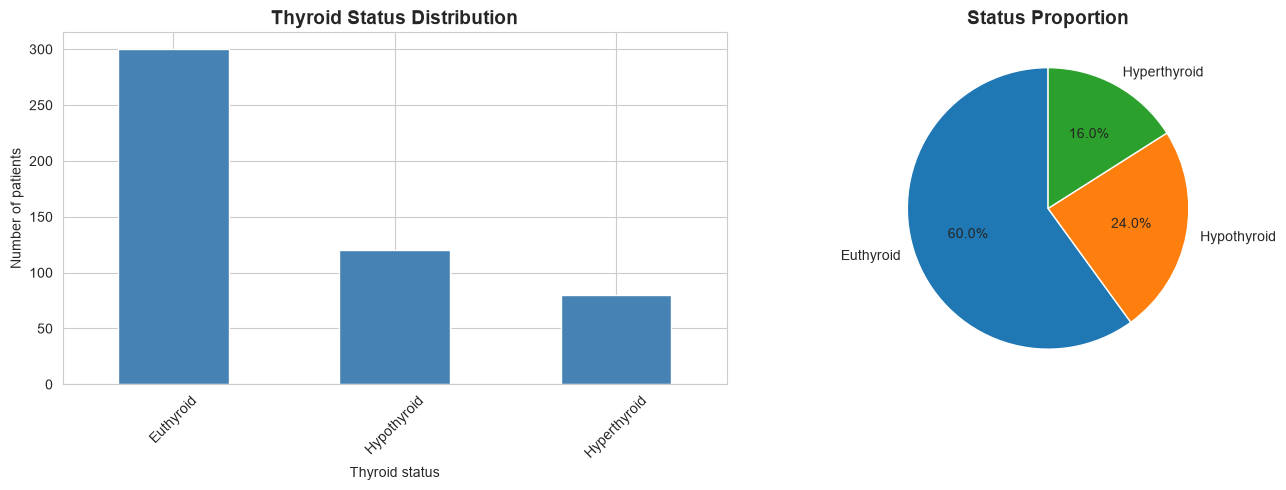


✅ Total patients: 500
✅ Balanced dataset: Moderately imbalanced
   Most people referred for thyroid testing turn out to be euthyroid, so a
   majority-normal cohort is what a real clinic looks like.

👥 Sex distribution within each status (%):


sex,F,M
thyroid_status,,
Euthyroid,55.7,44.3
Hyperthyroid,77.5,22.5
Hypothyroid,77.5,22.5


In [3]:
# Thyroid status distribution
print("🩺 Thyroid Status Distribution:")
status_counts = df['thyroid_status'].value_counts()
print(status_counts)

# Visualize status distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
status_counts.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Thyroid Status Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Thyroid status')
axes[0].set_ylabel('Number of patients')
axes[0].tick_params(axis='x', rotation=45)

# Pie chart
status_counts.plot(kind='pie', ax=axes[1], autopct='%1.1f%%', startangle=90)
axes[1].set_title('Status Proportion', fontsize=14, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print(f"\n✅ Total patients: {len(df)}")
print(f"✅ Balanced dataset: {'Yes' if status_counts.std() < status_counts.mean() * 0.5 else 'Moderately imbalanced'}")
print("   Most people referred for thyroid testing turn out to be euthyroid, so a")
print("   majority-normal cohort is what a real clinic looks like.")

# Sex distribution by status - autoimmune thyroid disease is much commoner in women
print("\n👥 Sex distribution within each status (%):")
display((pd.crosstab(df['thyroid_status'], df['sex'], normalize='index') * 100).round(1))


## 2. Feature Analysis

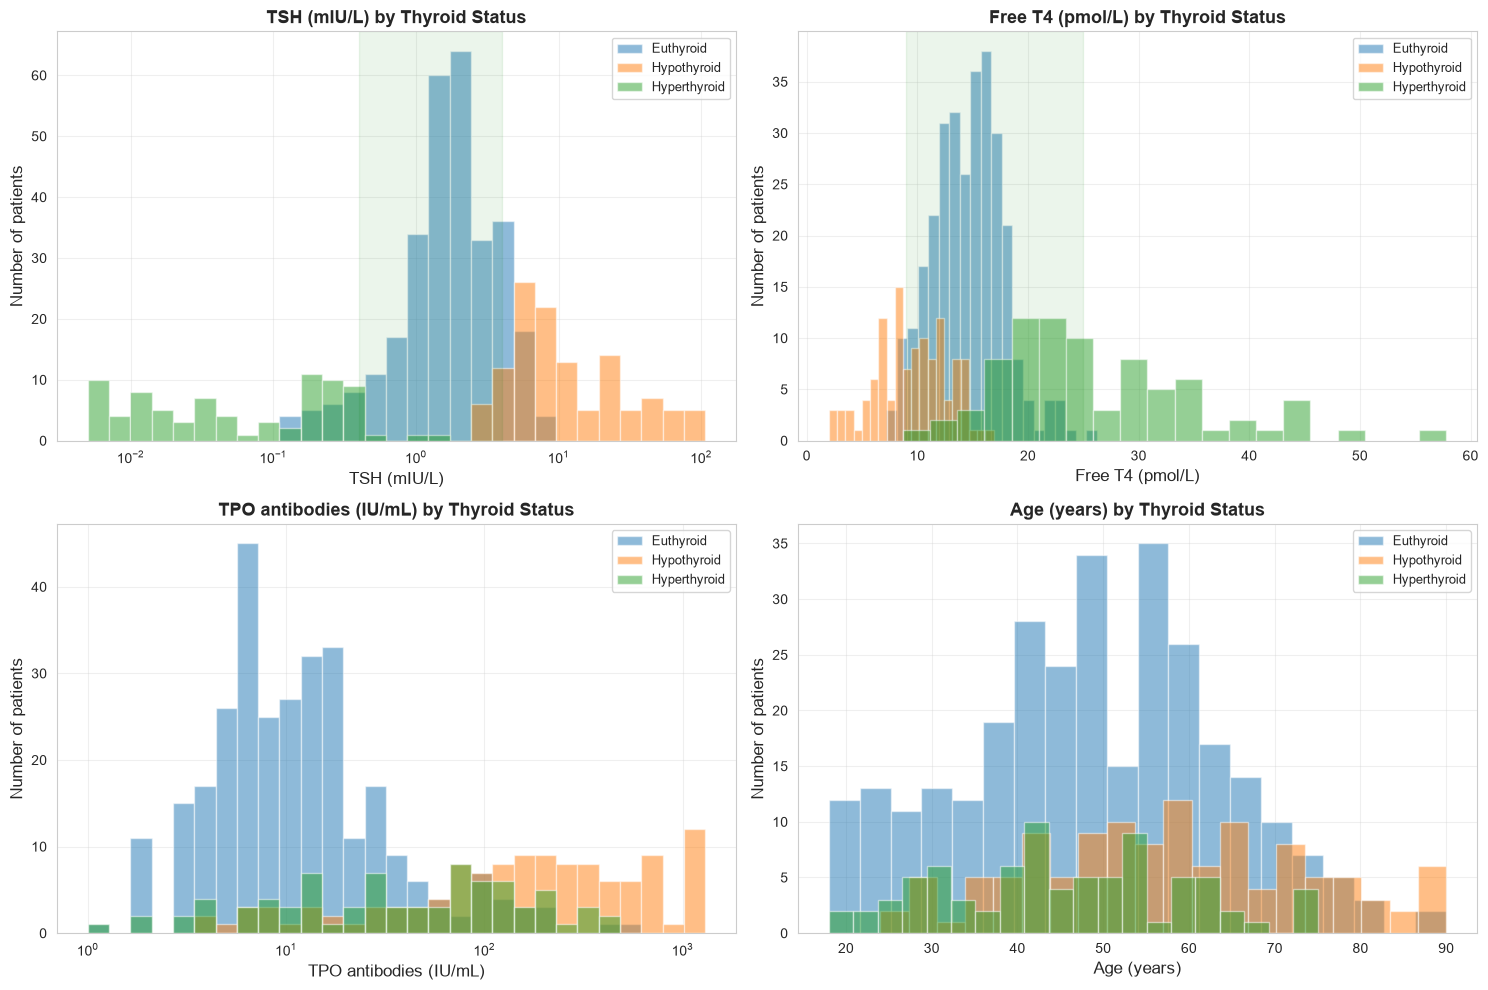

💡 The shaded band marks the adult reference range (TSH 0.4-4.0 mIU/L,
   free T4 9-25 pmol/L). Notice how much of each patient group still falls
   inside it - those are the subclinical cases, and they are what makes this
   classification harder than a single threshold.


In [4]:
# Visualize measurement distributions by thyroid status
features = ['tsh', 'free_t4', 'tpo_antibodies', 'age']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

for idx, feature in enumerate(features):
    # TSH and antibody titres span orders of magnitude, so bin and plot them on a log scale
    log_scale = feature in ('tsh', 'tpo_antibodies')
    if log_scale:
        bins = np.logspace(np.log10(df[feature].min()), np.log10(df[feature].max()), 30)
    else:
        bins = 20

    for status in ['Euthyroid', 'Hypothyroid', 'Hyperthyroid']:
        data = df[df['thyroid_status'] == status][feature]
        axes[idx].hist(data, alpha=0.5, label=status, bins=bins)

    if log_scale:
        axes[idx].set_xscale('log')

    axes[idx].set_xlabel(LABELS[feature], fontsize=12)
    axes[idx].set_ylabel('Number of patients', fontsize=12)
    axes[idx].set_title(f'{LABELS[feature]} by Thyroid Status', fontsize=13, fontweight='bold')
    axes[idx].legend(fontsize=9)
    axes[idx].grid(alpha=0.3)

# Mark the reference range on the two panels where it is meaningful
axes[0].axvspan(0.4, 4.0, color='green', alpha=0.08)
axes[1].axvspan(9.0, 25.0, color='green', alpha=0.08)

plt.tight_layout()
plt.show()

print("💡 The shaded band marks the adult reference range (TSH 0.4-4.0 mIU/L,")
print("   free T4 9-25 pmol/L). Notice how much of each patient group still falls")
print("   inside it - those are the subclinical cases, and they are what makes this")
print("   classification harder than a single threshold.")


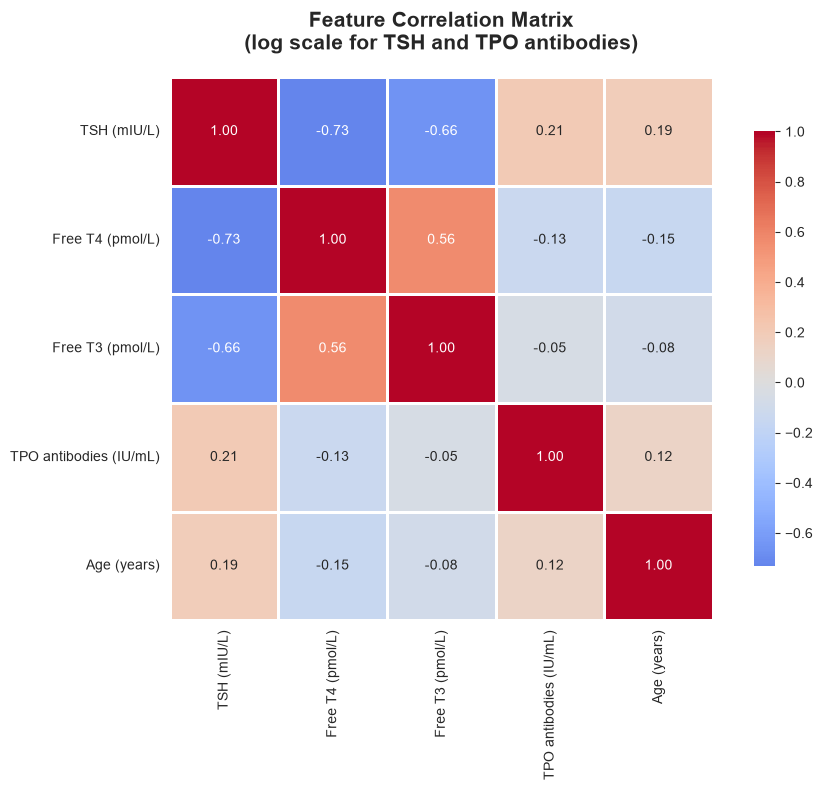


🔍 Key Observations:
- Free T4 and free T3 are strongly correlated: both are thyroid hormone output
- TSH moves in the OPPOSITE direction to free T4, which is the pituitary feedback loop
- TPO antibodies carry information the hormone levels do not: they point to an
  autoimmune cause rather than saying how the gland is performing right now


In [5]:
# Correlation heatmap
# TSH spans orders of magnitude, so correlate on the log scale where that is appropriate
plt.figure(figsize=(10, 8))
corr_frame = df[LAB_COLS].copy()
corr_frame['tsh'] = np.log10(corr_frame['tsh'])
corr_frame['tpo_antibodies'] = np.log10(corr_frame['tpo_antibodies'])
correlation_matrix = corr_frame.corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8},
            xticklabels=[LABELS[c] for c in LAB_COLS],
            yticklabels=[LABELS[c] for c in LAB_COLS])
plt.title('Feature Correlation Matrix\n(log scale for TSH and TPO antibodies)',
          fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n🔍 Key Observations:")
print("- Free T4 and free T3 are strongly correlated: both are thyroid hormone output")
print("- TSH moves in the OPPOSITE direction to free T4, which is the pituitary feedback loop")
print("- TPO antibodies carry information the hormone levels do not: they point to an")
print("  autoimmune cause rather than saying how the gland is performing right now")


📊 Median Values by Thyroid Status:


,TSH (mIU/L),Free T4 (pmol/L),Free T3 (pmol/L),TPO antibodies (IU/mL),Age (years)
thyroid_status,,,,,
Hypothyroid,8.00,9.6,3.90,173.0,57.0
Euthyroid,1.79,14.6,4.70,10.0,49.0
Hyperthyroid,0.05,24.3,7.55,42.0,45.0


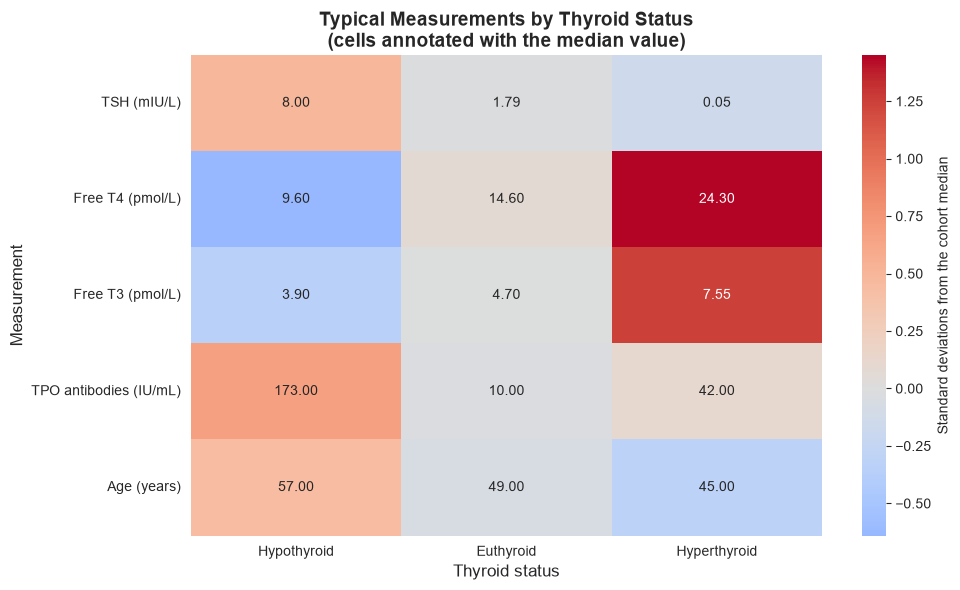


🧭 Read it left to right: as the gland goes from underactive to overactive,
   TSH falls and free T4 rises. That mirror image is the diagnostic signal.


In [6]:
# Typical values by thyroid status
# Medians, not means: TSH and antibody titres are heavily skewed
status_median = df.groupby('thyroid_status')[LAB_COLS].median().round(2)
status_median = status_median.loc[['Hypothyroid', 'Euthyroid', 'Hyperthyroid']]
print("📊 Median Values by Thyroid Status:")
display(status_median.rename(columns=LABELS))

# Visualize as a heatmap of z-scores, so measurements on different scales are comparable
plt.figure(figsize=(10, 6))
z = (status_median - df[LAB_COLS].median()) / df[LAB_COLS].std()
sns.heatmap(z.T, annot=status_median.T, fmt='.2f', cmap='coolwarm', center=0,
            cbar_kws={'label': 'Standard deviations from the cohort median'},
            yticklabels=[LABELS[c] for c in LAB_COLS])
plt.title('Typical Measurements by Thyroid Status\n(cells annotated with the median value)',
          fontsize=14, fontweight='bold')
plt.xlabel('Thyroid status', fontsize=12)
plt.ylabel('Measurement', fontsize=12)
plt.tight_layout()
plt.show()

print("\n🧭 Read it left to right: as the gland goes from underactive to overactive,")
print("   TSH falls and free T4 rises. That mirror image is the diagnostic signal.")


## 3. Prepare Data for Classification

In [7]:
# Select features for classification
# Using TSH, free T4, TPO antibodies and age.
# Free T3 is left out because it tracks free T4 closely (see the correlation matrix),
# and sex is left out because it is categorical and only shifts prior probability.
X = df[['tsh', 'free_t4', 'tpo_antibodies', 'age']]
y = df['thyroid_status']

# Split data into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("✅ Data prepared for classification:")
print(f"   - Training patients: {len(X_train)}")
print(f"   - Testing patients: {len(X_test)}")
print(f"   - Features used: {[LABELS[c] for c in X.columns]}")
print(f"   - Number of classes: {y.nunique()}")
print(f"   - Classes: {sorted(y.unique())}")


✅ Data prepared for classification:
   - Training patients: 400
   - Testing patients: 100
   - Features used: ['TSH (mIU/L)', 'Free T4 (pmol/L)', 'TPO antibodies (IU/mL)', 'Age (years)']
   - Number of classes: 3
   - Classes: ['Euthyroid', 'Hyperthyroid', 'Hypothyroid']


## 4. Build Decision Tree Classifier

In [8]:
# Create and train the decision tree classifier
# Using max_depth=4 to prevent overfitting while maintaining interpretability
dt_classifier = DecisionTreeClassifier(
    max_depth=4,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

# Train the model
dt_classifier.fit(X_train, y_train)

# Make predictions
y_train_pred = dt_classifier.predict(X_train)
y_test_pred = dt_classifier.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("🎯 Model Performance:")
print(f"   - Training Accuracy: {train_accuracy:.2%}")
print(f"   - Testing Accuracy: {test_accuracy:.2%}")
print(f"\n📊 Tree Structure:")
print(f"   - Depth: {dt_classifier.get_depth()}")
print(f"   - Number of leaves: {dt_classifier.get_n_leaves()}")
print(f"   - Number of nodes: {dt_classifier.tree_.node_count}")

🎯 Model Performance:
   - Training Accuracy: 97.25%
   - Testing Accuracy: 91.00%

📊 Tree Structure:
   - Depth: 4
   - Number of leaves: 12
   - Number of nodes: 23


In [9]:
# Detailed classification report
print("📋 Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred))

📋 Classification Report (Test Set):
              precision    recall  f1-score   support

   Euthyroid       0.90      0.95      0.93        60
Hyperthyroid       0.93      0.81      0.87        16
 Hypothyroid       0.91      0.88      0.89        24

    accuracy                           0.91       100
   macro avg       0.92      0.88      0.90       100
weighted avg       0.91      0.91      0.91       100



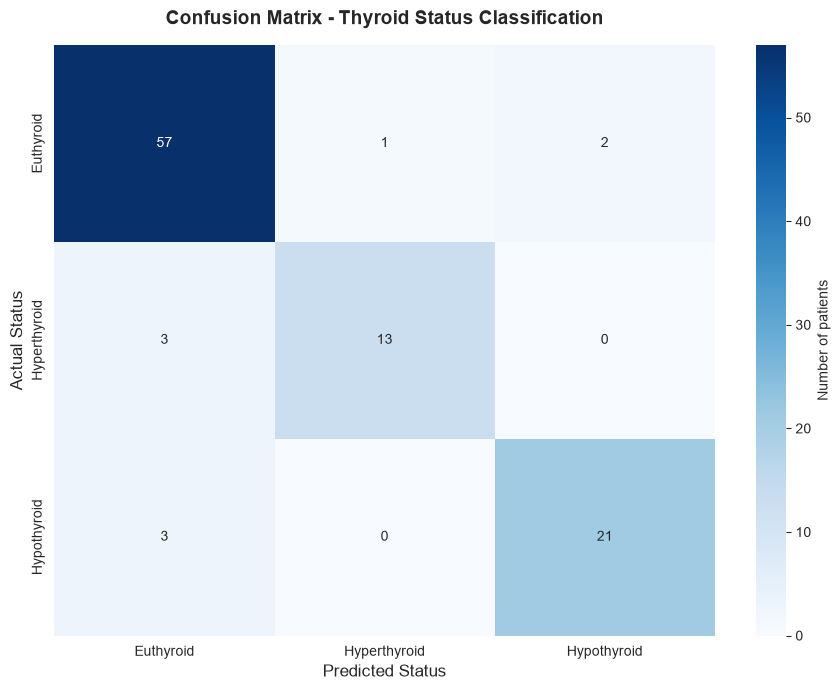


🔍 Confusion Matrix Interpretation:
- Diagonal values (dark blue) represent correct classifications
- Off-diagonal values show misclassifications
- The errors that matter here are subclinical cases called Euthyroid:
  a mildly raised TSH with a normal free T4 genuinely sits on the boundary,
  and in practice a clinician would repeat the panel rather than decide on one result


In [10]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred)
status_names = sorted(y.unique())

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=status_names, yticklabels=status_names,
            cbar_kws={'label': 'Number of patients'})
plt.title('Confusion Matrix - Thyroid Status Classification', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Status', fontsize=12)
plt.ylabel('Actual Status', fontsize=12)
plt.tight_layout()
plt.show()

print("\n🔍 Confusion Matrix Interpretation:")
print("- Diagonal values (dark blue) represent correct classifications")
print("- Off-diagonal values show misclassifications")
print("- The errors that matter here are subclinical cases called Euthyroid:")
print("  a mildly raised TSH with a normal free T4 genuinely sits on the boundary,")
print("  and in practice a clinician would repeat the panel rather than decide on one result")


## 5. Feature Importance Analysis

⭐ Feature Importance:


,Feature,Importance
0,TSH (mIU/L),0.739336
1,Free T4 (pmol/L),0.144768
2,TPO antibodies (IU/mL),0.115896
3,Age (years),0.000000


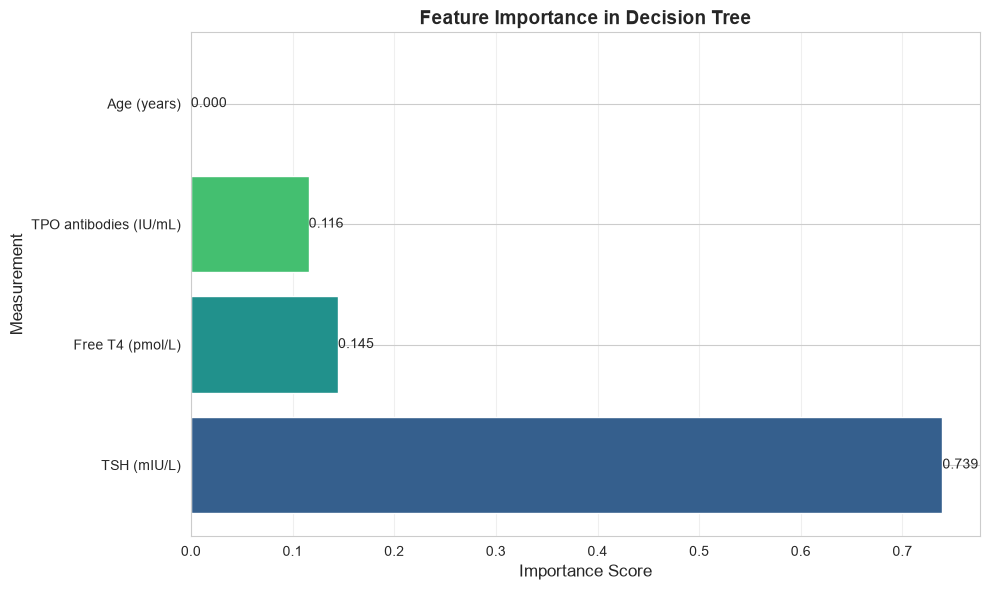


💡 Insights:
   - Most important measurement: TSH (mIU/L)
   - Least important measurement: Age (years)
   - TSH leading is the expected result: it is the most sensitive single marker of
     thyroid status, which is exactly why it is the standard first-line test.


In [11]:
# Feature importance
feature_importance = pd.DataFrame({
    'Feature': [LABELS[c] for c in X.columns],
    'Importance': dt_classifier.feature_importances_
}).sort_values('Importance', ascending=False)

print("⭐ Feature Importance:")
display(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(feature_importance)))
bars = plt.barh(feature_importance['Feature'], feature_importance['Importance'], color=colors)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Measurement', fontsize=12)
plt.title('Feature Importance in Decision Tree', fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)

# Add value labels on bars
for bar in bars:
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height()/2,
             f'{width:.3f}', ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

print("\n💡 Insights:")
print(f"   - Most important measurement: {feature_importance.iloc[0]['Feature']}")
print(f"   - Least important measurement: {feature_importance.iloc[-1]['Feature']}")
print("   - TSH leading is the expected result: it is the most sensitive single marker of")
print("     thyroid status, which is exactly why it is the standard first-line test.")


## 6. Visualize the Decision Tree

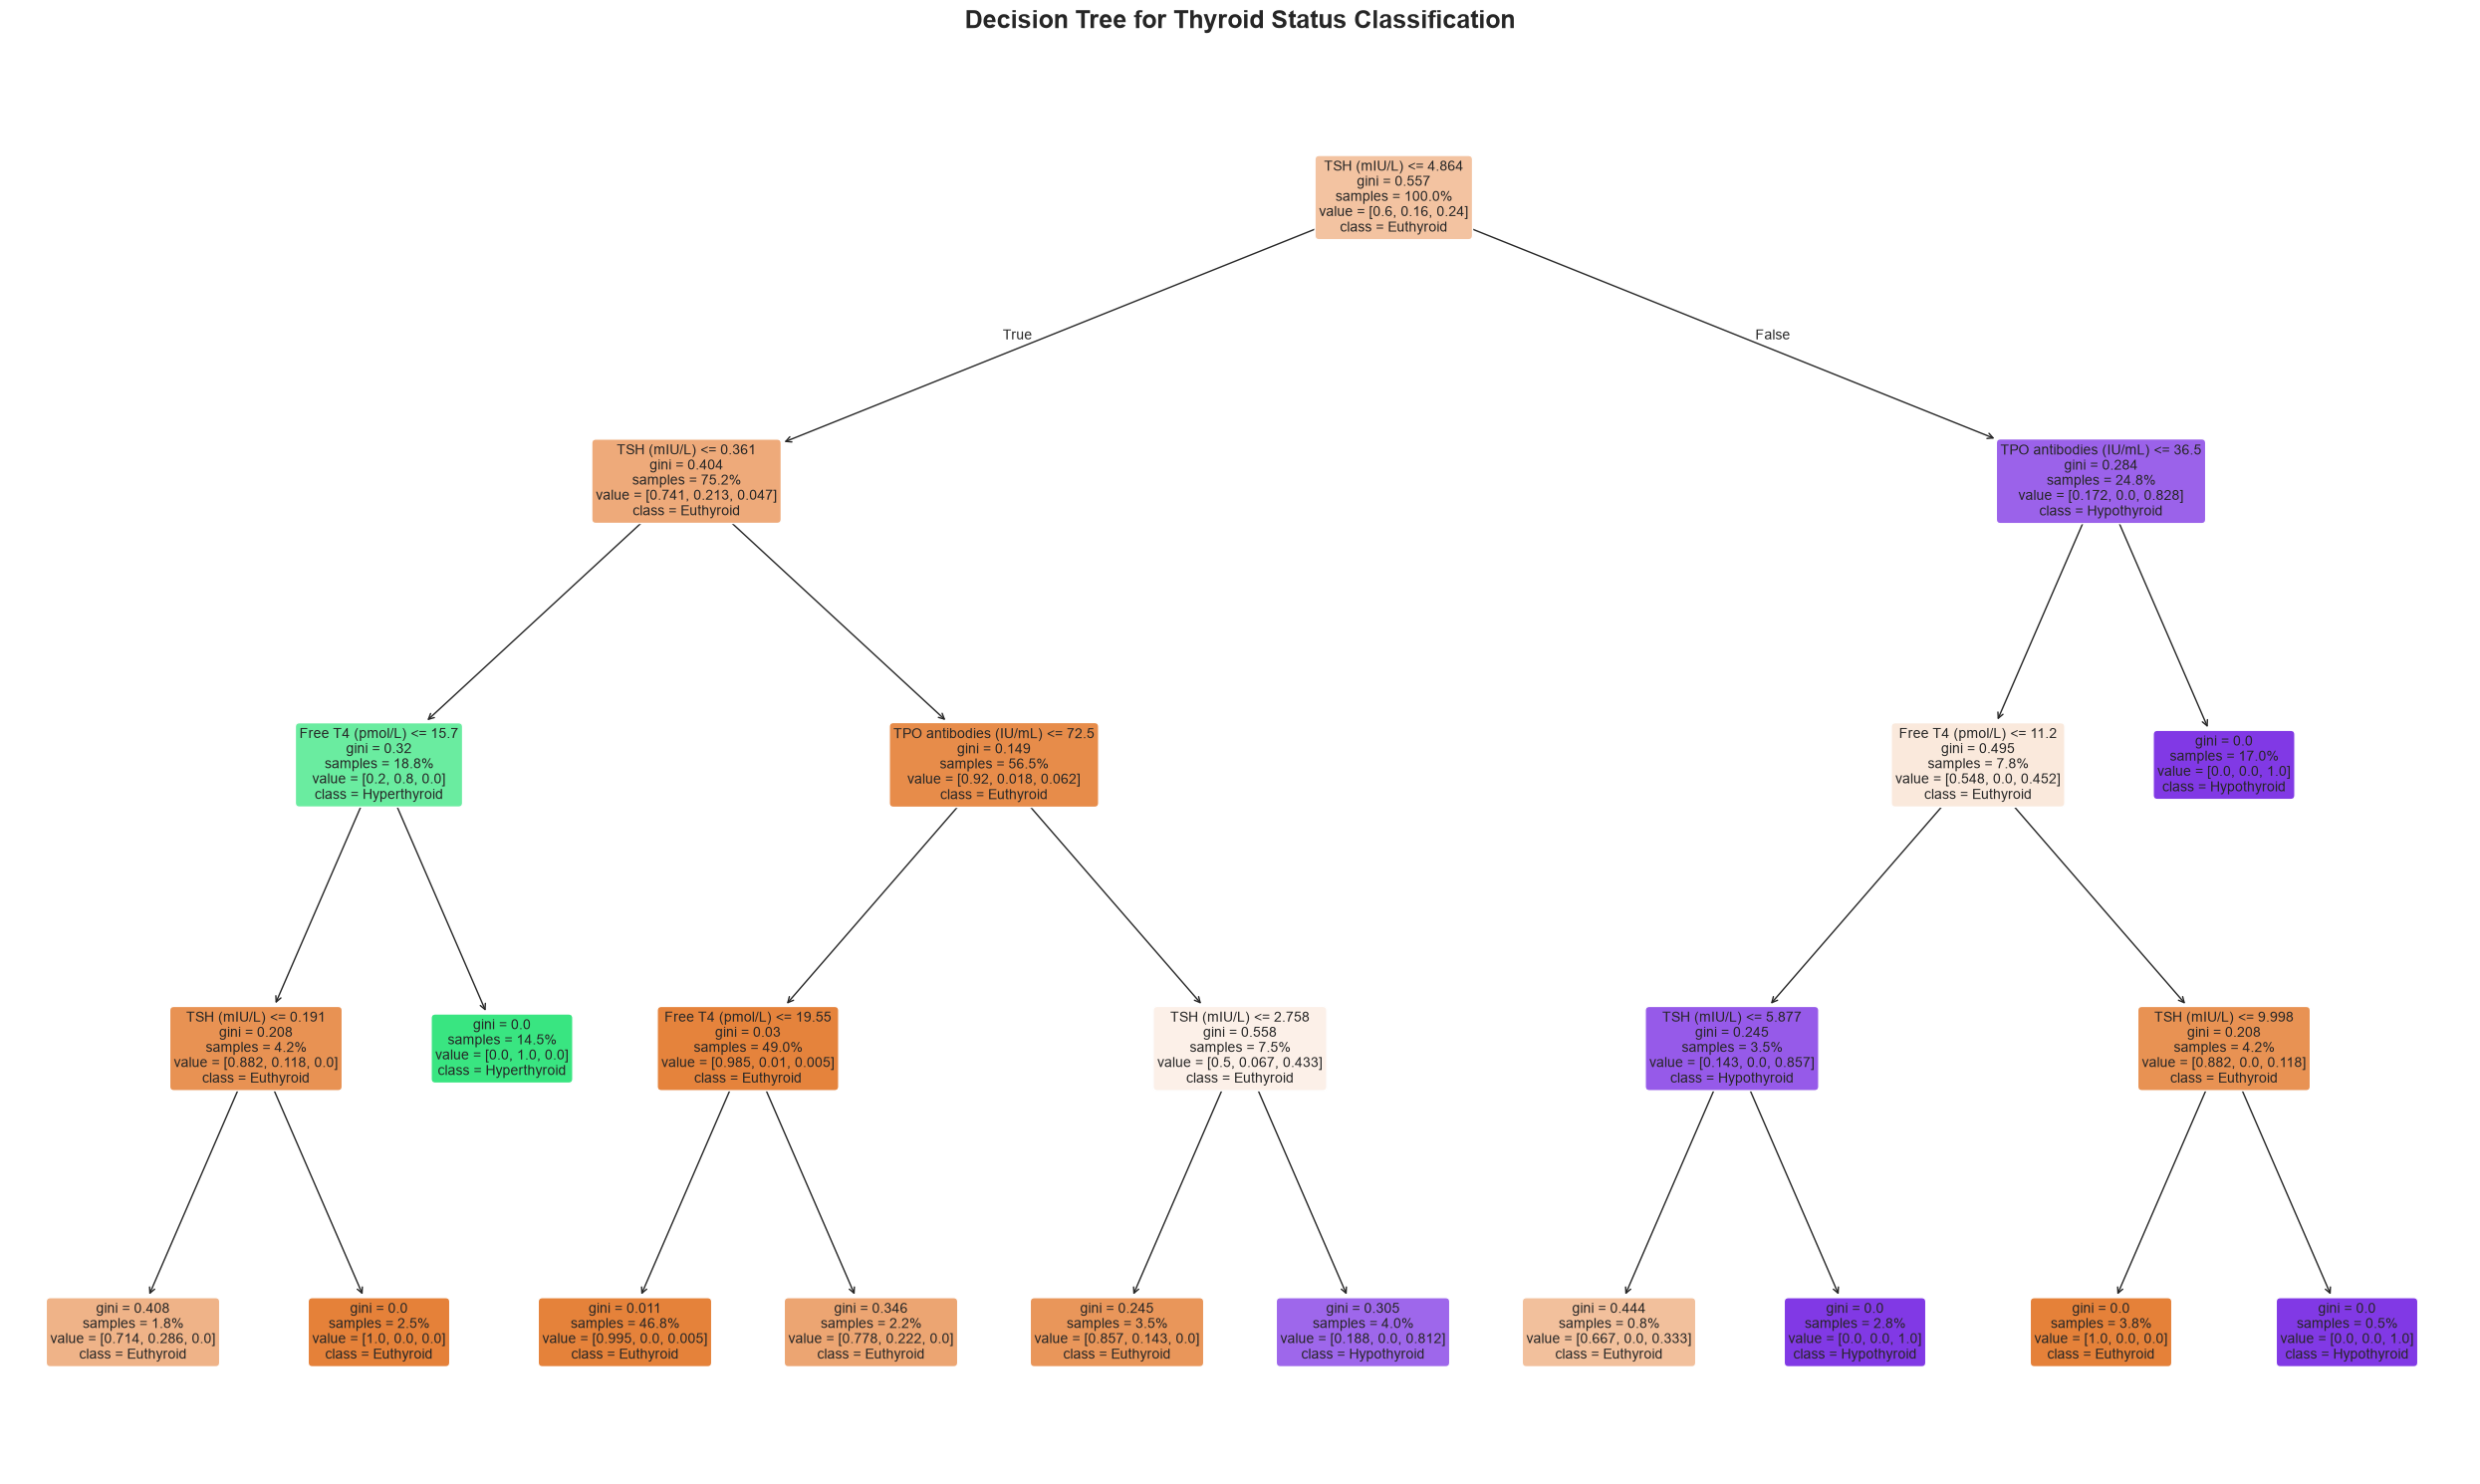


🌳 How to read the tree:
   - Each box is a node with a decision rule or classification
   - Top line: Decision rule (e.g. 'TSH (mIU/L) <= 4.15')
   - Second line: Gini impurity (measure of node purity)
   - Third line: Number of samples at this node
   - Fourth line: Class distribution
   - Fifth line: Predicted class
   - Colors: Intensity shows confidence in prediction

🧪 Compare the learned thresholds against the reference ranges (TSH 0.4-4.0,
   free T4 9-25). A model that splits close to the clinical cut-points is one a
   clinician can sanity-check, and that is the whole point of using a tree here.


In [12]:
# Visualize the decision tree
plt.figure(figsize=(25, 15))
plot_tree(dt_classifier,
          feature_names=[LABELS[c] for c in X.columns],
          class_names=sorted(y.unique()),
          filled=True,
          rounded=True,
          fontsize=10,
          proportion=True)
plt.title('Decision Tree for Thyroid Status Classification', fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n🌳 How to read the tree:")
print("   - Each box is a node with a decision rule or classification")
print("   - Top line: Decision rule (e.g. 'TSH (mIU/L) <= 4.15')")
print("   - Second line: Gini impurity (measure of node purity)")
print("   - Third line: Number of samples at this node")
print("   - Fourth line: Class distribution")
print("   - Fifth line: Predicted class")
print("   - Colors: Intensity shows confidence in prediction")
print("\n🧪 Compare the learned thresholds against the reference ranges (TSH 0.4-4.0,")
print("   free T4 9-25). A model that splits close to the clinical cut-points is one a")
print("   clinician can sanity-check, and that is the whole point of using a tree here.")


In [13]:
# Export tree rules as text
tree_rules = export_text(dt_classifier, feature_names=list(X.columns))
print("📝 Decision Tree Rules (Text Format):")
print(tree_rules)

📝 Decision Tree Rules (Text Format):
|--- tsh <= 4.86
|   |--- tsh <= 0.36
|   |   |--- free_t4 <= 15.70
|   |   |   |--- tsh <= 0.19
|   |   |   |   |--- class: Euthyroid
|   |   |   |--- tsh >  0.19
|   |   |   |   |--- class: Euthyroid
|   |   |--- free_t4 >  15.70
|   |   |   |--- class: Hyperthyroid
|   |--- tsh >  0.36
|   |   |--- tpo_antibodies <= 72.50
|   |   |   |--- free_t4 <= 19.55
|   |   |   |   |--- class: Euthyroid
|   |   |   |--- free_t4 >  19.55
|   |   |   |   |--- class: Euthyroid
|   |   |--- tpo_antibodies >  72.50
|   |   |   |--- tsh <= 2.76
|   |   |   |   |--- class: Euthyroid
|   |   |   |--- tsh >  2.76
|   |   |   |   |--- class: Hypothyroid
|--- tsh >  4.86
|   |--- tpo_antibodies <= 36.50
|   |   |--- free_t4 <= 11.20
|   |   |   |--- tsh <= 5.88
|   |   |   |   |--- class: Euthyroid
|   |   |   |--- tsh >  5.88
|   |   |   |   |--- class: Hypothyroid
|   |   |--- free_t4 >  11.20
|   |   |   |--- tsh <= 10.00
|   |   |   |   |--- class: Euthyroid
|   |

## 7. Compare Different Tree Depths

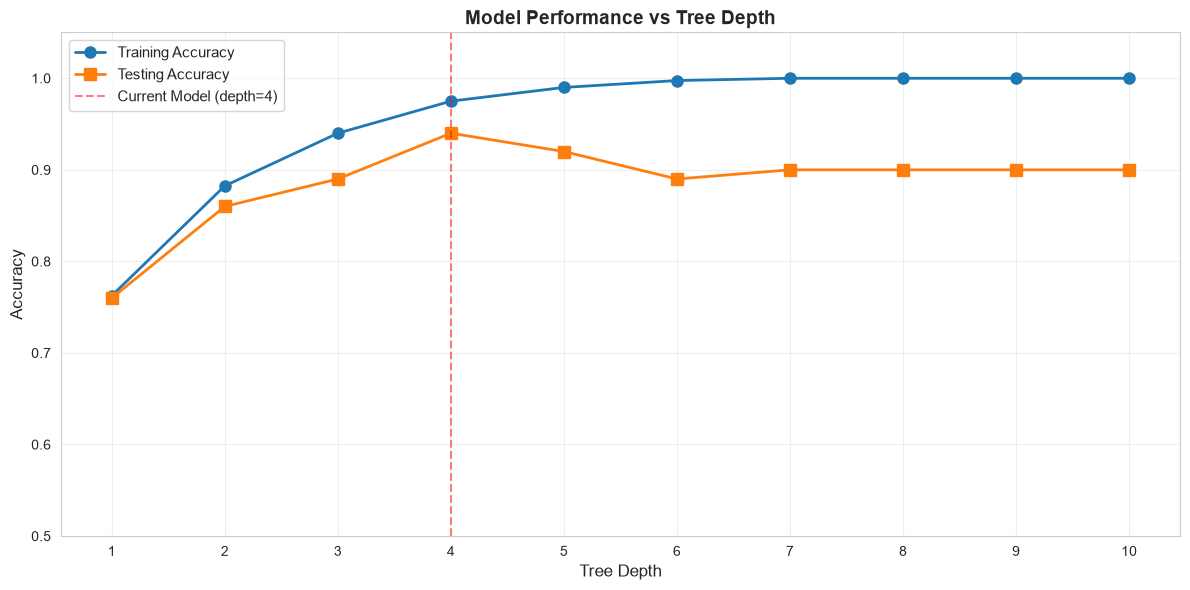


📊 Overfitting Analysis:
   - Best test accuracy: 94.00% at depth 4
   - Current model (depth=4) test accuracy: 94.00%
   - Overfitting at depth=10: 10.00% gap between train and test

🧭 A deep tree eventually carves out one leaf per borderline patient. In a
   clinic that is worthless: those patients are borderline because the assay is
   noisy, not because there is a rule waiting to be found.


In [14]:
# Train models with different depths
depths = range(1, 11)
train_scores = []
test_scores = []

for depth in depths:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train, y_train)
    train_scores.append(dt.score(X_train, y_train))
    test_scores.append(dt.score(X_test, y_test))

# Plot the results
plt.figure(figsize=(12, 6))
plt.plot(depths, train_scores, 'o-', label='Training Accuracy', linewidth=2, markersize=8)
plt.plot(depths, test_scores, 's-', label='Testing Accuracy', linewidth=2, markersize=8)
plt.axvline(x=4, color='red', linestyle='--', alpha=0.5, label='Current Model (depth=4)')
plt.xlabel('Tree Depth', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Model Performance vs Tree Depth', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.xticks(depths)
plt.ylim([0.5, 1.05])
plt.tight_layout()
plt.show()

print("\n📊 Overfitting Analysis:")
print(f"   - Best test accuracy: {max(test_scores):.2%} at depth {depths[test_scores.index(max(test_scores))]}")
print(f"   - Current model (depth=4) test accuracy: {test_scores[3]:.2%}")
gap = train_scores[-1] - test_scores[-1]
print(f"   - Overfitting at depth=10: {gap:.2%} gap between train and test")
print("\n🧭 A deep tree eventually carves out one leaf per borderline patient. In a")
print("   clinic that is worthless: those patients are borderline because the assay is")
print("   noisy, not because there is a rule waiting to be found.")


## 8. Classify New Patient Presentations


In [15]:
# Select some test patients to visualize predictions
sample_indices = [0, 5, 10, 15, 20]
samples = X_test.iloc[sample_indices]
actual_status = y_test.iloc[sample_indices]
predictions = dt_classifier.predict(samples)
probabilities = dt_classifier.predict_proba(samples)

print("🩺 Sample Classifications:\n")
for i, (idx, pred, actual) in enumerate(zip(sample_indices, predictions, actual_status)):
    print(f"Patient {i+1}:")
    print(f"  Panel: TSH={samples.iloc[i]['tsh']:.2f} mIU/L, "
          f"free T4={samples.iloc[i]['free_t4']:.1f} pmol/L, "
          f"TPO Ab={samples.iloc[i]['tpo_antibodies']:.0f} IU/mL, "
          f"age={samples.iloc[i]['age']:.0f} y")
    print(f"  Predicted: {pred}")
    print(f"  Actual: {actual}")
    print(f"  Correct: {'✅ Yes' if pred == actual else '❌ No'}")
    print(f"  Confidence: {max(probabilities[i]):.1%}")
    print()

print("⚠️  A model output is not a diagnosis. Thyroid status is confirmed on a repeat")
print("   panel and in the context of the patient's symptoms, medication and pregnancy status.")


🩺 Sample Classifications:

Patient 1:
  Panel: TSH=2.66 mIU/L, free T4=16.6 pmol/L, TPO Ab=210 IU/mL, age=57 y
  Predicted: Euthyroid
  Actual: Euthyroid
  Correct: ✅ Yes
  Confidence: 85.7%

Patient 2:
  Panel: TSH=0.02 mIU/L, free T4=34.1 pmol/L, TPO Ab=85 IU/mL, age=39 y
  Predicted: Hyperthyroid
  Actual: Hyperthyroid
  Correct: ✅ Yes
  Confidence: 100.0%

Patient 3:
  Panel: TSH=39.50 mIU/L, free T4=7.2 pmol/L, TPO Ab=35 IU/mL, age=52 y
  Predicted: Hypothyroid
  Actual: Hypothyroid
  Correct: ✅ Yes
  Confidence: 100.0%

Patient 4:
  Panel: TSH=2.44 mIU/L, free T4=14.8 pmol/L, TPO Ab=5 IU/mL, age=47 y
  Predicted: Euthyroid
  Actual: Euthyroid
  Correct: ✅ Yes
  Confidence: 99.5%

Patient 5:
  Panel: TSH=0.18 mIU/L, free T4=15.4 pmol/L, TPO Ab=16 IU/mL, age=54 y
  Predicted: Euthyroid
  Actual: Euthyroid
  Correct: ✅ Yes
  Confidence: 71.4%

⚠️  A model output is not a diagnosis. Thyroid status is confirmed on a repeat
   panel and in the context of the patient's symptoms, medicat

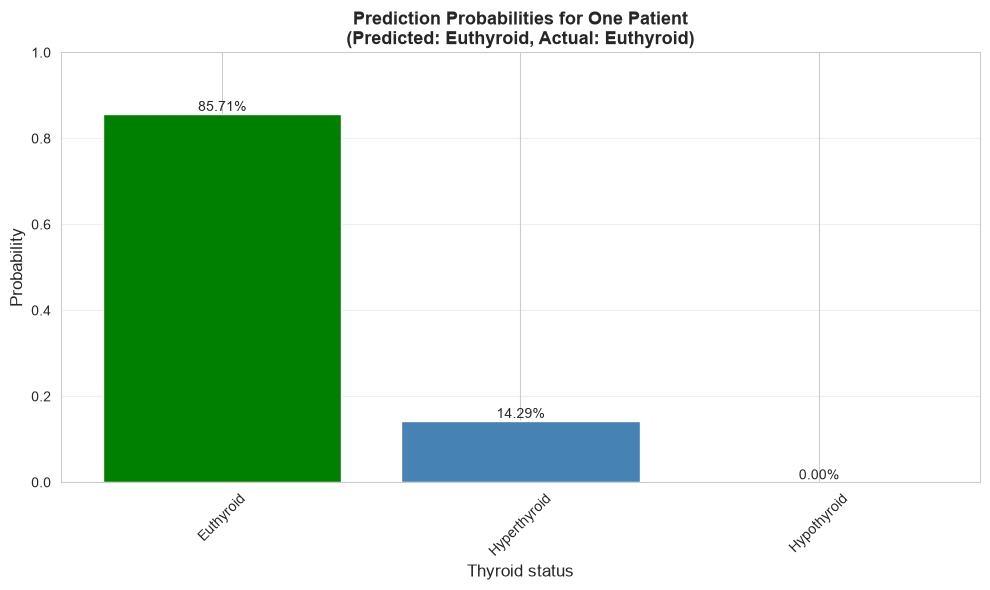

In [16]:
# Visualize prediction probabilities for one patient
sample_idx = 0
sample_probs = probabilities[sample_idx]
status_names_sorted = sorted(y.unique())

plt.figure(figsize=(10, 6))
colors = ['green' if prob == max(sample_probs) else 'steelblue' for prob in sample_probs]
bars = plt.bar(status_names_sorted, sample_probs, color=colors)
plt.xlabel('Thyroid status', fontsize=12)
plt.ylabel('Probability', fontsize=12)
plt.title('Prediction Probabilities for One Patient\n'
          f'(Predicted: {predictions[sample_idx]}, Actual: {actual_status.iloc[sample_idx]})',
          fontsize=13, fontweight='bold')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.ylim([0, 1])

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2%}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


## 9. Export Model Rules


In [17]:
# Extract decision rules from the tree so they can be reviewed or reused outside the notebook
import json

def extract_tree_rules(tree, feature_names):
    """Extract decision rules from sklearn decision tree"""
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != -2 else "undefined!"
        for i in tree_.feature
    ]

    rules = []

    def recurse(node, depth=0):
        if tree_.feature[node] != -2:  # Not a leaf
            name = feature_name[node]
            threshold = tree_.threshold[node]
            rules.append({
                'node': int(node),
                'feature': name,
                'threshold': float(threshold),
                'samples': int(tree_.n_node_samples[node]),
                'is_leaf': False
            })
            recurse(tree_.children_left[node], depth + 1)
            recurse(tree_.children_right[node], depth + 1)
        else:  # Leaf node
            value = tree_.value[node]
            class_idx = np.argmax(value)
            rules.append({
                'node': int(node),
                'prediction': sorted(y.unique())[class_idx],
                'samples': int(tree_.n_node_samples[node]),
                'is_leaf': True
            })

    recurse(0)
    return rules

# Extract rules, labelled with the clinical measurement names and units
tree_rules_dict = extract_tree_rules(dt_classifier, [LABELS[c] for c in X.columns])

# Save to JSON file
with open('../../thyroid_tree_rules.json', 'w') as f:
    json.dump(tree_rules_dict, f, indent=2)

print("✅ Decision tree rules exported to 'thyroid_tree_rules.json'")
print(f"\n📊 Exported {len(tree_rules_dict)} nodes")
print(f"   - Decision nodes: {sum(1 for r in tree_rules_dict if not r['is_leaf'])}")
print(f"   - Leaf nodes: {sum(1 for r in tree_rules_dict if r['is_leaf'])}")
print("\n💡 Exported rules are readable: each one is a threshold on a named")
print("   measurement, which a clinician can check against the reference ranges.")


✅ Decision tree rules exported to 'thyroid_tree_rules.json'

📊 Exported 23 nodes
   - Decision nodes: 11
   - Leaf nodes: 12

💡 Exported rules are readable: each one is a threshold on a named
   measurement, which a clinician can check against the reference ranges.


## 🎓 Key Takeaways

### What We Learned:
1. **Decision Trees** split data on measurement thresholds to classify patients
2. **Feature Importance** shows which parts of the thyroid panel carry the diagnosis
3. **Tree Depth** controls model complexity:
   - Shallow trees: Simple but may underfit
   - Deep trees: Complex but may overfit the assay noise
4. **Gini Impurity** measures node purity (0 = pure, higher = mixed)
5. **Confusion Matrix** reveals which statuses are confused with each other - here, almost
   always the subclinical cases against Euthyroid

### Why this problem suits a tree
The learned thresholds can be laid alongside the published reference ranges and checked.
A model whose first split is TSH near 4 mIU/L is reasoning the way the guidelines do; a
model that split first on age would be telling you something was wrong with the data.

### Real-World Applications:
- 🩺 Endocrinology: thyroid, adrenal and pituitary function panels
- 🏥 Triage: routing abnormal lab results to the right clinic
- 🧪 Laboratory medicine: flagging panels that need a repeat sample
- 💊 Pharmacovigilance: spotting drug effects on thyroid function

### A necessary caveat
This is a teaching example on simulated data. A model used in care would need validation
on a real, prospectively collected cohort, checks that it performs equally across age and
sex, and a defined place in a workflow where a clinician makes the decision.

### Next Steps:
- Try different `max_depth` values
- Add free T3 and sex back in and see whether they help
- Compare with Random Forests (ensemble of trees)
- Add SHAP values for detailed prediction explanations


## 10. Interactive Exploration with Widgets

Use interactive widgets to explore how different tree parameters affect performance.

In [18]:
from ipywidgets import interact, IntSlider, Dropdown
import ipywidgets as widgets

@interact(
    max_depth=IntSlider(min=1, max=10, value=4, description="Max Depth:"),
    min_samples_split=IntSlider(min=2, max=20, value=5, description="Min Split:"),
    min_samples_leaf=IntSlider(min=1, max=10, value=2, description="Min Leaf:")
)
def explore_tree_parameters(max_depth=4, min_samples_split=5, min_samples_leaf=2):
    # Train model with selected parameters
    dt = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        random_state=42
    )
    dt.fit(X_train, y_train)
    
    train_acc = dt.score(X_train, y_train)
    test_acc = dt.score(X_test, y_test)
    
    print(f"🎯 Training Accuracy: {train_acc:.2%}")
    print(f"🎯 Testing Accuracy: {test_acc:.2%}")
    print(f"📊 Tree Depth: {dt.get_depth()}")
    print(f"🍃 Number of Leaves: {dt.get_n_leaves()}")
    print(f"📈 Overfitting Gap: {(train_acc - test_acc):.2%}")

interactive(children=(IntSlider(value=4, description='Max Depth:', max=10, min=1), IntSlider(value=5, descript…

## 11. Model Interpretation with SHAP Values

SHAP (SHapley Additive exPlanations) values help us understand how each feature contributes to individual predictions.

In [19]:
import shap

# Create SHAP explainer
explainer = shap.TreeExplainer(dt_classifier)
shap_values = explainer.shap_values(X_test)

# Class order follows the fitted classifier, which is what the SHAP arrays are indexed by
class_names = list(dt_classifier.classes_)

print("✅ SHAP values computed successfully!")
print(f"   Shape: {np.shape(shap_values)}  (patients x measurements x classes)")
print(f"   Classes: {class_names}")


✅ SHAP values computed successfully!
   Shape: (100, 4, 3)  (patients x measurements x classes)
   Classes: ['Euthyroid', 'Hyperthyroid', 'Hypothyroid']


<Figure size 1200x800 with 0 Axes>

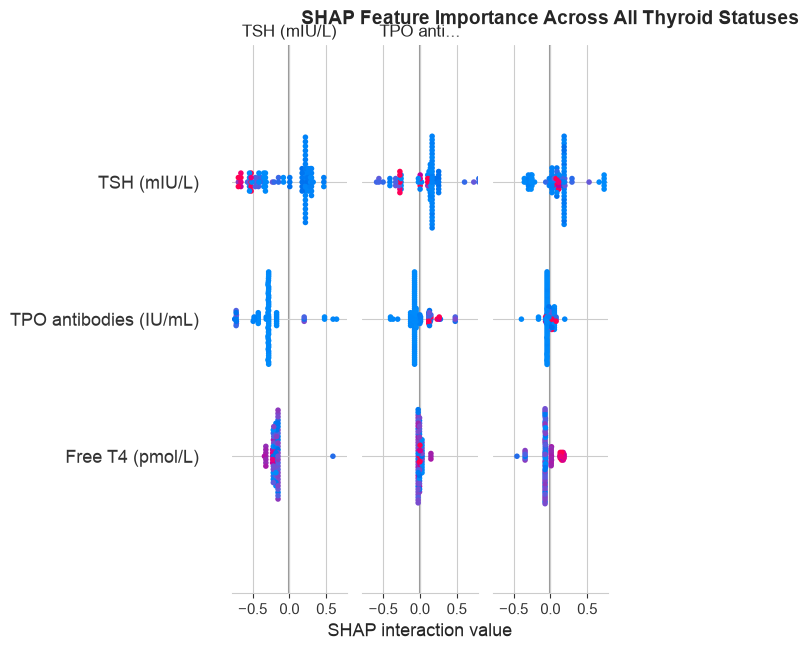


📊 SHAP Summary Plot Interpretation:
   - Bar length is the average size of a measurement's contribution
   - Colours split that contribution by predicted class
   - Measurements are ordered by overall importance
   - TSH dominating across all three classes is the clinically expected result


In [20]:
# SHAP summary plot (global feature importance)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test, feature_names=[LABELS[c] for c in X.columns],
                  class_names=class_names, show=False)
plt.title("SHAP Feature Importance Across All Thyroid Statuses", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

print("\n📊 SHAP Summary Plot Interpretation:")
print("   - Bar length is the average size of a measurement's contribution")
print("   - Colours split that contribution by predicted class")
print("   - Measurements are ordered by overall importance")
print("   - TSH dominating across all three classes is the clinically expected result")


🩺 Explaining the classification for test patient 0:
   Actual status: Euthyroid
   Predicted status: Euthyroid
   Panel: TSH=2.66 mIU/L, free T4=16.6 pmol/L, TPO Ab=210 IU/mL, age=57 y



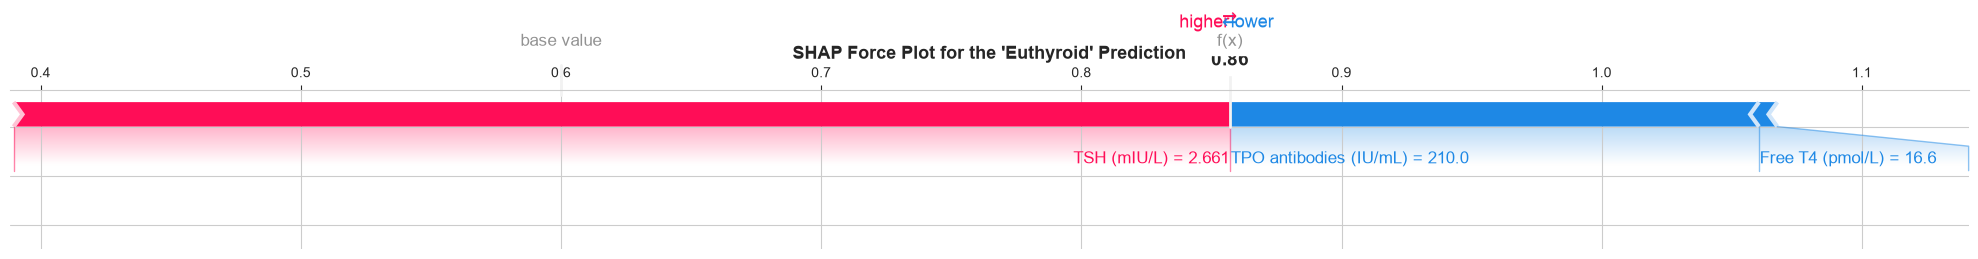


💡 Force Plot Interpretation:
   - Red measurements push the prediction toward this status
   - Blue measurements push the prediction away from it
   - Base value is the average model output for this status
   - Output value is the final score for this patient

   This is the part a clinician would actually look at: not just what the model
   said, but which number on the panel made it say so.


In [21]:
# Explain an individual patient's classification
sample_idx = 0
sample = X_test.iloc[sample_idx:sample_idx+1]
actual = y_test.iloc[sample_idx]
predicted = dt_classifier.predict(sample)[0]
predicted_idx = class_names.index(predicted)

print(f"🩺 Explaining the classification for test patient {sample_idx}:")
print(f"   Actual status: {actual}")
print(f"   Predicted status: {predicted}")
print(f"   Panel: TSH={sample.iloc[0]['tsh']:.2f} mIU/L, "
      f"free T4={sample.iloc[0]['free_t4']:.1f} pmol/L, "
      f"TPO Ab={sample.iloc[0]['tpo_antibodies']:.0f} IU/mL, "
      f"age={sample.iloc[0]['age']:.0f} y")
print()

# Force plot for this prediction
shap.initjs()
shap.force_plot(
    explainer.expected_value[predicted_idx],
    shap_values[sample_idx, :, predicted_idx],
    sample.rename(columns=LABELS),
    matplotlib=True,
    show=False
)
plt.title(f"SHAP Force Plot for the '{predicted}' Prediction", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("\n💡 Force Plot Interpretation:")
print("   - Red measurements push the prediction toward this status")
print("   - Blue measurements push the prediction away from it")
print("   - Base value is the average model output for this status")
print("   - Output value is the final score for this patient")
print("\n   This is the part a clinician would actually look at: not just what the model")
print("   said, but which number on the panel made it say so.")


## 🎉 Conclusion

Congratulations! You have successfully:

1. ✅ Generated and explored a simulated thyroid function cohort
2. ✅ Built a decision tree classifier for three thyroid statuses
3. ✅ Visualized the tree structure and decision rules
4. ✅ Analyzed feature importance
5. ✅ Compared different tree depths
6. ✅ Used interactive widgets for parameter exploration
7. ✅ Interpreted predictions with SHAP values
8. ✅ Exported the learned rules as JSON for review

### 🚀 Next Steps:

- **Try Random Forests:** Ensemble of multiple decision trees
- **Experiment with XGBoost:** Advanced gradient boosting (see `s2_05_xgboost_tutorial.ipynb`)
- **Feature Engineering:** Try the free T4 to TSH ratio, or a log-TSH feature
- **Cross-Validation:** More robust performance evaluation on a small cohort
- **Check calibration:** a probability of 0.7 should be right about 70% of the time

### 📚 Additional Resources:

- [scikit-learn Decision Trees](https://scikit-learn.org/stable/modules/tree.html)
- [SHAP Documentation](https://shap.readthedocs.io/)
- Exported decision rules: `thyroid_tree_rules.json` (written in section 9)


In [22]:
# Where the exported rules ended up
import os
rules_path = os.path.abspath("../../thyroid_tree_rules.json")
print("📄 Exported Decision Rules:")
print(f"   File: {rules_path}")
print("\n   👉 Each entry is one node: a threshold on a named measurement, or a leaf")
print("      with the status it predicts. Open it to read the model as a list of rules,")
print("      or feed it to a visualization of your own.")


📄 Exported Decision Rules:
   File: /Users/randygiffen/Library/CloudStorage/OneDrive-IBM/Python/ai-fundamentals-healthcare/thyroid_tree_rules.json

   👉 Each entry is one node: a threshold on a named measurement, or a leaf
      with the status it predicts. Open it to read the model as a list of rules,
      or feed it to a visualization of your own.
